# 01 - Data exploration

**Question:** What is in the GA4 sample, and what does a normal day look like?

**Inputs:** exported aggregates in `data/exports/` (made by `scripts/export_from_bigquery.py`).
**Units used here:** event rows, users (distinct `user_pseudo_id`) and user-days. They are different things and are never mixed in one number.

> If the first cell prints a *SYNTHETIC DEMO DATA* warning, the numbers below are invented test data. Export the real sample before writing any finding.

In [1]:
# --- Setup: run this cell first ---
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "productpulse").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from productpulse import data, metrics, charts

charts.apply_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

print(data.data_banner())

Real BigQuery export loaded from: C:\Users\Padmashree\OneDrive\Desktop\ProductPulse-AI\ProductPulse-AI\data\exports


## 1. Load and inspect the tables

In [2]:
overview = data.load("dataset_overview")
events = data.load("event_overview")
daily = data.load("daily_metrics")
fact, dim = data.load_model()

for name, df in [("dataset_overview", overview), ("event_overview", events),
                 ("daily_metrics", daily), ("fact_user_day", fact), ("dim_user", dim)]:
    print(f"{name:<18} rows = {len(df):>9,}   columns = {df.shape[1]}")

display(overview.T.rename(columns={0: "value"}))

dataset_overview   rows =         1   columns = 9
event_overview     rows =        17   columns = 3
daily_metrics      rows =        92   columns = 7
fact_user_day      rows =   319,066   columns = 12
dim_user           rows =   270,154   columns = 10


,value
first_event_date,2020-11-01 00:00:00
last_event_date,2021-01-31 00:00:00
days_with_data,92
event_rows,4295584
identified_users,270154
null_user_id_rows,0
null_session_id_rows,0
sessions,360129
distinct_event_names,17


In [3]:
print("fact_user_day: one row per user per active day")
display(fact.head())
display(fact.dtypes.to_frame("dtype").T)

print("dim_user: one row per user")
display(dim.head())
print("Missing values per column:")
display(pd.concat([fact.isna().sum().rename("fact_user_day"), dim.isna().sum().rename("dim_user")], axis=1).fillna("-"))

fact_user_day: one row per user per active day


,user_pseudo_id,event_dt,events,sessions,page_views,engagement_sec,viewed_item,added_cart,began_checkout,purchased,transactions,revenue_usd
0,1021793.7381839042,2020-11-01,13,1,4,78.3000,0,0,0,0,0,0.0000
1,1055429.2539666160,2020-11-01,6,2,2,0.0000,0,0,0,0,0,0.0000
2,1059048.1097852879,2020-11-01,8,1,2,12.6000,0,0,0,0,0,0.0000
3,1076509.6896049246,2020-11-01,16,2,4,9.4000,0,0,0,0,0,0.0000
4,1120828.7450351953,2020-11-01,9,1,3,57.1000,0,0,0,0,0,0.0000


,user_pseudo_id,event_dt,events,sessions,page_views,engagement_sec,viewed_item,added_cart,began_checkout,purchased,transactions,revenue_usd
dtype,string[python],datetime64[ns],int64,int64,int64,float64,int64,int64,int64,int64,int64,float64


dim_user: one row per user


,user_pseudo_id,first_seen_dt,last_seen_dt,cohort_month,device_category,country,first_user_source,first_user_medium,channel_group,n_devices
0,33467389.6528078571,2020-12-08,2021-01-05,2020-12-01,desktop,Singapore,(data deleted),(data deleted),Data deleted,2
1,51222284.3516228368,2020-12-27,2020-12-27,2020-12-01,desktop,South Korea,(data deleted),(data deleted),Data deleted,1
2,60819436.6999078377,2020-11-17,2021-01-16,2020-11-01,desktop,Israel,(data deleted),(data deleted),Data deleted,1
3,75415589.6215353764,2020-12-27,2020-12-27,2020-12-01,desktop,United States,(data deleted),(data deleted),Data deleted,1
4,90646004.4180451996,2020-12-14,2020-12-27,2020-12-01,desktop,United States,(data deleted),(data deleted),Data deleted,1


Missing values per column:


,fact_user_day,dim_user
user_pseudo_id,0.0000,0.0000
event_dt,0.0000,-
events,0.0000,-
sessions,0.0000,-
page_views,0.0000,-
engagement_sec,0.0000,-
viewed_item,0.0000,-
added_cart,0.0000,-
began_checkout,0.0000,-
purchased,0.0000,-


## 2. Date coverage\nThe public sample should cover 2020-11-01 to 2021-01-31 (92 days) with no missing days.

In [4]:
first_day, last_day = daily["event_dt"].min(), daily["event_dt"].max()
expected_days = pd.date_range(first_day, last_day, freq="D")
missing_days = expected_days.difference(daily["event_dt"])

print(f"First day : {first_day.date()}")
print(f"Last day  : {last_day.date()}")
print(f"Days with data: {daily['event_dt'].nunique()} of {len(expected_days)} calendar days")
print("Missing days:", [d.date().isoformat() for d in missing_days] or "none")
PERIOD = f"{first_day.date()} to {last_day.date()}"

First day : 2020-11-01
Last day  : 2021-01-31
Days with data: 92 of 92 calendar days
Missing days: none


## 3. Which events exist?\n`event_rows` counts rows. `users` counts distinct users who fired the event at least once. A user can fire `page_view` many times, so the two columns answer different questions.

,event_name,event_rows,users,pct_of_rows,rows_per_user
0,page_view,"1,350,428","269,792",31.4%,5.01
1,user_engagement,"1,058,721","213,004",24.6%,4.97
2,scroll,"493,072","138,098",11.5%,3.57
3,view_item,"386,068","61,252",9.0%,6.30
4,session_start,"354,970","267,116",8.3%,1.33
5,first_visit,"257,462","257,314",6.0%,1.00
6,view_promotion,"190,104","102,443",4.4%,1.86
7,add_to_cart,"58,543","12,545",1.4%,4.67
8,begin_checkout,"38,757","9,715",0.9%,3.99
9,select_item,"31,007","13,180",0.7%,2.35


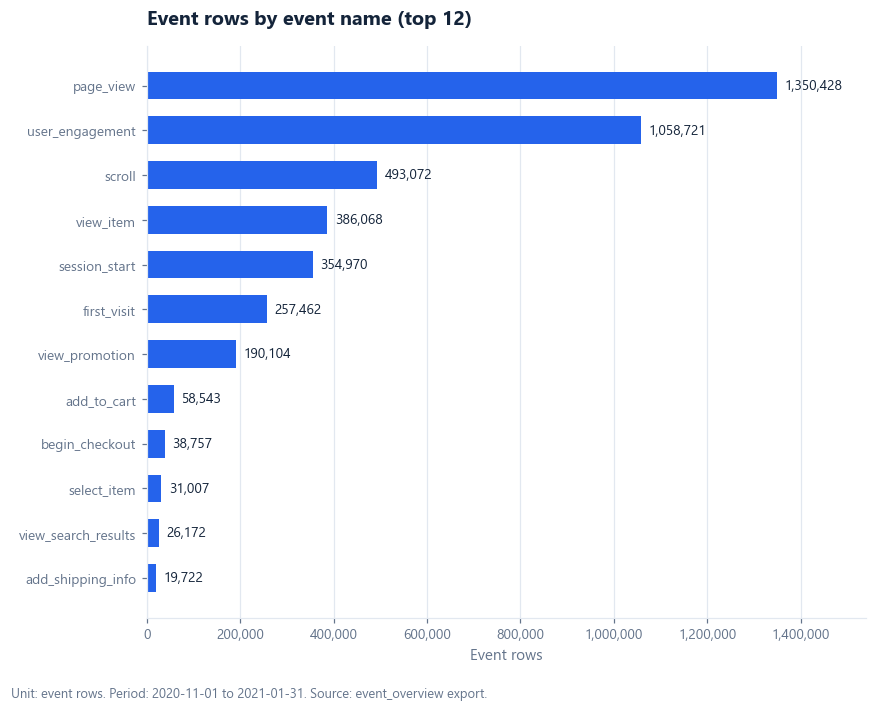

Funnel events present: ['view_item', 'add_to_cart', 'begin_checkout', 'purchase']
Funnel events missing: none


In [5]:
events["pct_of_rows"] = events["event_rows"] / events["event_rows"].sum()
events["rows_per_user"] = events["event_rows"] / events["users"]
display(events.style.format({"event_rows": "{:,.0f}", "users": "{:,.0f}",
                             "pct_of_rows": "{:.1%}", "rows_per_user": "{:.2f}"}))

top = events.head(12)
fig, ax = charts.bar_chart(top["event_name"], top["event_rows"],
                           "Event rows by event name (top 12)", "Event rows")
charts.note(fig, f"Unit: event rows. Period: {PERIOD}. Source: event_overview export.")
charts.save_figure(fig, "01_event_rows")
plt.show()

funnel_events = ["view_item", "add_to_cart", "begin_checkout", "purchase"]
present = [e for e in funnel_events if e in set(events["event_name"])]
print("Funnel events present:", present)
print("Funnel events missing:", [e for e in funnel_events if e not in present] or "none")

**Interpretation (write this yourself after running on the real export)**

- *Observation:* which three events make up most rows, and how rare the four funnel events are next to `page_view`.
- *Possible explanation (unproven):* browsing events fire automatically on every page; commerce events need a deliberate action.
- *Next check:* confirm the funnel-stage mapping in `data/data_dictionary.md` matches the event names above.

## 4. Daily activity

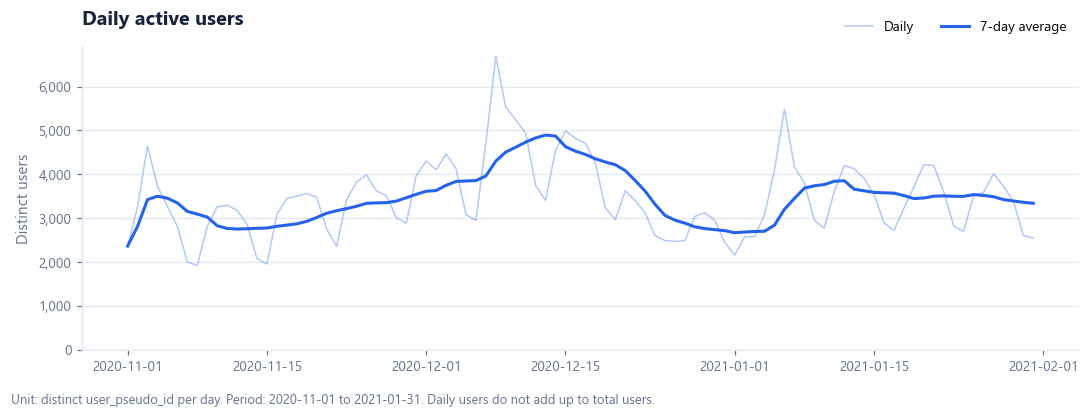

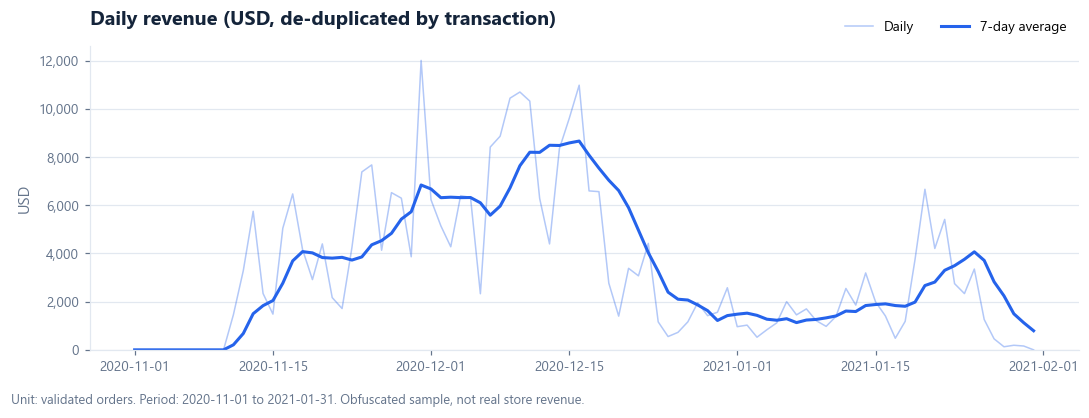

Busiest day : 2020-12-08 with 6,689 active users
Quietest day: 2020-11-08 with 1,919 active users
Highest average weekday: Tuesday (4,099); lowest: Sunday (2,615)


,total_events,transactions,revenue_usd
event_dt,,,
2020-11-01 00:00:00,"1,472,712","1,258","93,320"
2020-12-01 00:00:00,"1,612,725","2,304","158,370"
2021-01-01 00:00:00,"1,210,147",889,"56,510"


In [6]:
fig, ax = charts.line_chart(daily, "event_dt", "active_users",
                            "Daily active users", "Distinct users", rolling=7)
charts.note(fig, f"Unit: distinct user_pseudo_id per day. Period: {PERIOD}. "
                 "Daily users do not add up to total users.")
charts.save_figure(fig, "01_daily_active_users")
plt.show()

fig, ax = charts.line_chart(daily, "event_dt", "revenue_usd",
                            "Daily revenue (USD, de-duplicated by transaction)", "USD", rolling=7)
charts.note(fig, f"Unit: validated orders. Period: {PERIOD}. Obfuscated sample, not real store revenue.")
charts.save_figure(fig, "01_daily_revenue")
plt.show()

peak = daily.loc[daily["active_users"].idxmax()]
low = daily.loc[daily["active_users"].idxmin()]
by_weekday = daily.assign(weekday=daily["event_dt"].dt.day_name()).groupby("weekday")["active_users"].mean()
print(f"Busiest day : {peak['event_dt'].date()} with {peak['active_users']:,} active users")
print(f"Quietest day: {low['event_dt'].date()} with {low['active_users']:,} active users")
print(f"Highest average weekday: {by_weekday.idxmax()} ({by_weekday.max():,.0f}); "
      f"lowest: {by_weekday.idxmin()} ({by_weekday.min():,.0f})")
monthly = daily.set_index("event_dt").resample("MS")[["total_events", "transactions", "revenue_usd"]].sum()
display(monthly.style.format("{:,.0f}"))

**Interpretation (write this yourself after running on the real export)**

- *Observation:* the trend across November, December and January, the busiest and quietest days, and any weekday pattern.
- *Possible explanation (unproven):* holiday shopping season (late November and December) and weekday office browsing are candidates.
- *Next check:* compare the trend by device and channel in notebook 03 before drawing any conclusion.

## 5. How active is a typical user?

,count,mean,std,min,50%,90%,99%,max
active_days,"270,154.00",1.18,0.66,1.00,1.00,2.00,4.00,12.00
events,"270,154.00",15.90,39.03,1.00,6.00,28.00,220.47,"1,309.00"
sessions,"270,154.00",1.34,1.01,1.00,1.00,2.00,6.00,13.00


Users active on exactly one day: 89.0% of 270,154 users


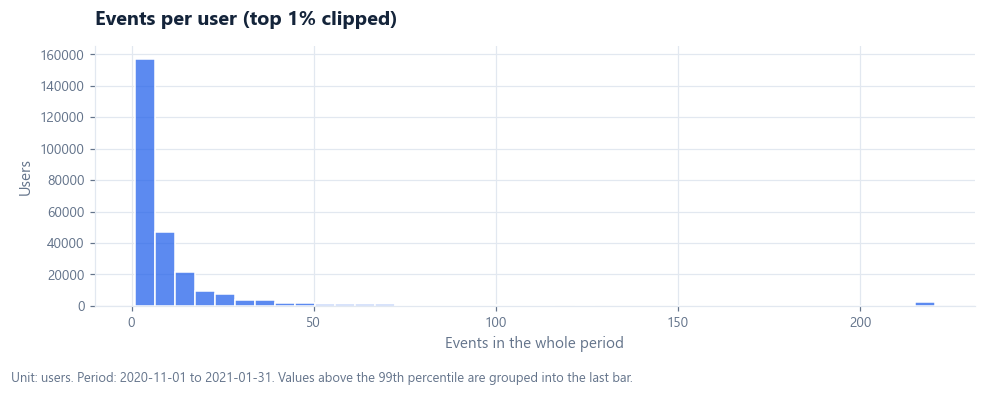

In [7]:
per_user = fact.groupby("user_pseudo_id").agg(active_days=("event_dt", "nunique"),
                                              events=("events", "sum"),
                                              sessions=("sessions", "sum"))
display(per_user.describe(percentiles=[0.5, 0.9, 0.99]).T.style.format("{:,.2f}"))

share_one_day = (per_user["active_days"] == 1).mean()
print(f"Users active on exactly one day: {share_one_day:.1%} of {len(per_user):,} users")

fig, ax = plt.subplots(figsize=(9, 3.4))
sns.histplot(per_user["events"].clip(upper=per_user["events"].quantile(0.99)), bins=40,
             color=charts.BLUE, edgecolor="white", ax=ax)
ax.set_title("Events per user (top 1% clipped)")
ax.set_xlabel("Events in the whole period")
ax.set_ylabel("Users")
charts.note(fig, f"Unit: users. Period: {PERIOD}. Values above the 99th percentile are grouped into the last bar.")
plt.show()

**Interpretation (write this yourself after running on the real export)**

- *Observation:* the share of single-day users and how skewed events per user are (median vs 99th percentile).
- *Possible explanation (unproven):* many visitors are one-off browsers; a small group of heavy users may include staff or bots.
- *Next check:* inspect the heaviest users in notebook 02 (outliers) before using averages.

## 6. Who are the users? Device, country and channel mix\nEach user is assigned the device and country of their **first observed event**. Channel is GA4's user-level first-touch source.

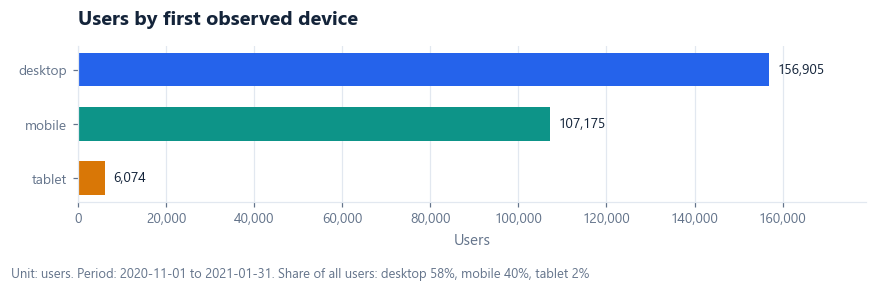

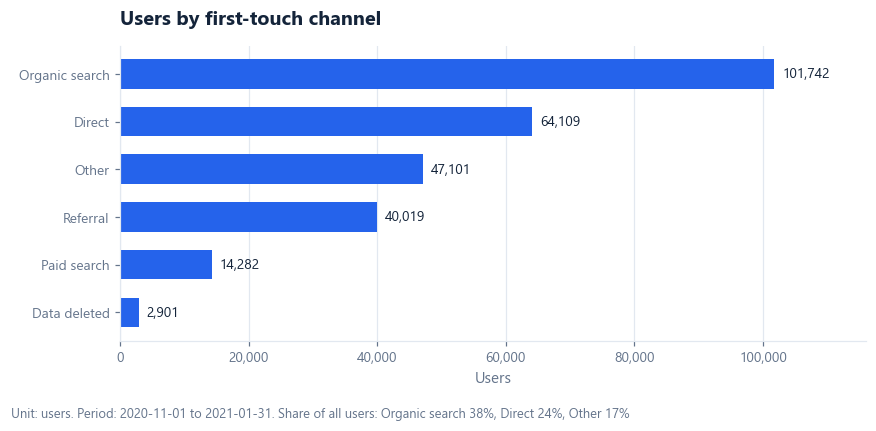

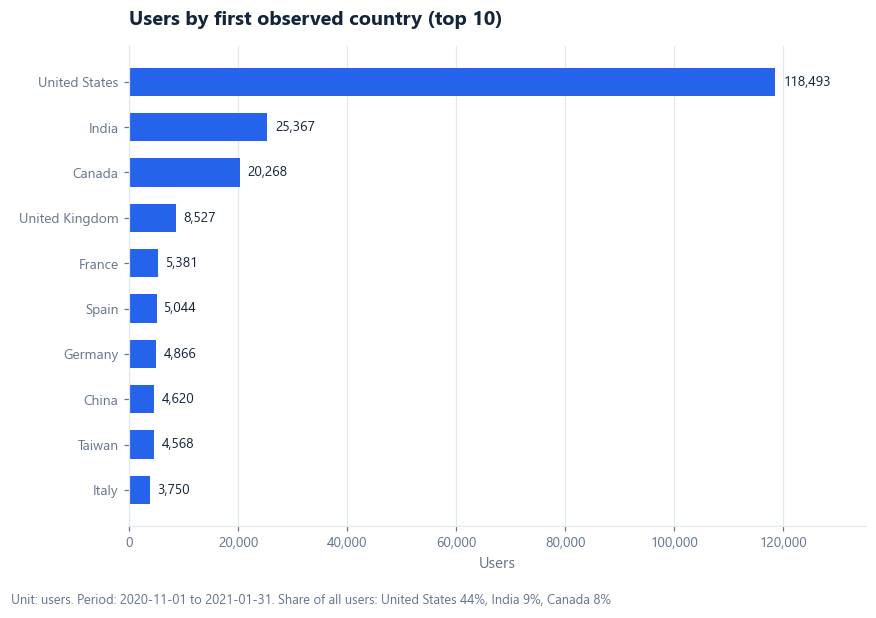

Users whose channel is an obfuscation artefact ('Other' or 'Data deleted'): 18.5%


In [8]:
for column, title in [("device_category", "Users by first observed device"),
                      ("channel_group", "Users by first-touch channel"),
                      ("country", "Users by first observed country (top 10)")]:
    counts = dim[column].value_counts().head(10)
    colours = [charts.DEVICE_COLOURS.get(v, charts.BLUE) for v in counts.index] if column == "device_category" else None
    fig, ax = charts.bar_chart(counts.index, counts.values, title, "Users", colours=colours)
    charts.note(fig, f"Unit: users. Period: {PERIOD}. Share of all users: "
                     + ", ".join(f"{k} {v / len(dim):.0%}" for k, v in counts.head(3).items()))
    charts.save_figure(fig, f"01_users_by_{column}")
    plt.show()

obfuscated = dim["channel_group"].isin(["Other", "Data deleted"]).mean()
print(f"Users whose channel is an obfuscation artefact ('Other' or 'Data deleted'): {obfuscated:.1%}")

**Interpretation (write this yourself after running on the real export)**

- *Observation:* the device split, the top countries and how large the obfuscated channel groups are.
- *Possible explanation (unproven):* the store's audience and the dataset's anonymisation both shape these mixes.
- *Next check:* treat channel comparisons with caution if the obfuscated share is large (see notebook 03).

## Summary of this notebook

Fill this in with the real numbers once the export has run:

| Item | Value | Where it comes from |
|---|---|---|
| Date range | | section 2 |
| Event rows / users / sessions | | section 1 (`dataset_overview`) |
| Share of single-day users | | section 5 |
| Largest device / channel | | section 6 |